**Сначала переключитесь на графический процессор!**

# 6. Практическое занятие. Свёрточные нейронные сети (CNN)

**Цель работы:** Познакомиться с архитектурой CNN, научиться строить и обучать свёрточные сети для классификации изображений, визуализировать карты активации и экспериментировать с архитектурными решениями.

В этой практике мы будем использовать датасет CIFAR-10 (32x32 цветных изображения, 10 классов).

## 0. Импорты и подготовка данных

Импортируем необходимые библиотеки и загружаем CIFAR-10.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import time

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

# Устройство
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')



Using device: cuda


In [2]:
# Загрузка данных CIFAR-10
# Для ускорения возьмём подвыборку (первые 10000 обучающих, 2000 тестовых)
# Но можно и полный датасет, если есть время.

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

train_full = datasets.CIFAR10('./data', train=True, download=True, transform=transform)
test_full = datasets.CIFAR10('./data', train=False, download=True, transform=transform)

# Для экспериментов возьмём подвыборку (ускорит обучение)
num_train = 10000
num_val = 2000
indices = torch.randperm(len(train_full))
train_indices = indices[:num_train]
val_indices = indices[num_train:num_train+num_val]

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(train_full, val_indices)
test_dataset = test_full

print(f'Train samples: {len(train_dataset)}')
print(f'Val samples: {len(val_dataset)}')
print(f'Test samples: {len(test_dataset)}')

Files already downloaded and verified


Files already downloaded and verified


Train samples: 10000
Val samples: 2000
Test samples: 10000


In [3]:
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

print(f'Train size: {len(train_dataset)}, Test size: {len(test_dataset)}')

Train size: 10000, Test size: 10000


## 1. Построение базовой CNN (10 мин)

Определим класс `SimpleCNN` с двумя свёрточными слоями, пулингом и полносвязными слоями.

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)  # 32x32 -> 32x32
        self.pool = nn.MaxPool2d(2)                               # 32x32 -> 16x16
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1) # 16x16 -> 16x16
        # После второго пулинга: 64 канала * 8 * 8
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        # x - входное изображение.
        x = self.pool(F.relu(self.conv1(x)))
        # теперь x - 32 карты признаков размером 16x16
        x = self.pool(F.relu(self.conv2(x)))
        # теперь x - 64 карты признаков размером 8x8

        # растягиваем тензор 64х8х8 в один большой вектор.
        x = x.view(x.size(0), -1)  # flatten

        x = self.dropout(F.relu(self.fc1(x)))
        # теперь х - вектор из 256 результатов активации нейронов
        x = self.fc2(x)
        # теперь х - вектор из 10 чисел, имеющих значения (-inf; inf).
        # Т.к. ниже написан выбор кросс-энтропии в качестве функции потерь
        # для многоклассовой классификации
        # criterion = nn.CrossEntropyLoss()
        # то к х после завершения данного метода
        # ещё дополнительно применится функция softmaх,
        # которая отмасштабирует значения х до отрезка [0; 1]
        return x

model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Посчитаем количество параметров
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Количество обучаемых параметров: {count_parameters(model)}')

Количество обучаемых параметров: 1070794


## 2. Обучение и базовая оценка

Напишем функцию для одной эпохи обучения и оценки. Обучим модель на 5 эпохах и сохраним историю потерь.

Epoch 1/5, Train Loss: 1.8090, Val Loss: 1.4586, Val Acc: 0.4829


Epoch 2/5, Train Loss: 1.4197, Val Loss: 1.3016, Val Acc: 0.5314


Epoch 3/5, Train Loss: 1.2491, Val Loss: 1.2049, Val Acc: 0.5707


Epoch 4/5, Train Loss: 1.1186, Val Loss: 1.1447, Val Acc: 0.5925


Epoch 5/5, Train Loss: 1.0209, Val Loss: 1.1068, Val Acc: 0.6091

Финальная точность на тесте: 0.6091
Сравнение с MLP: CNN обычно работает лучше, потому что использует локальность и разделение весов.


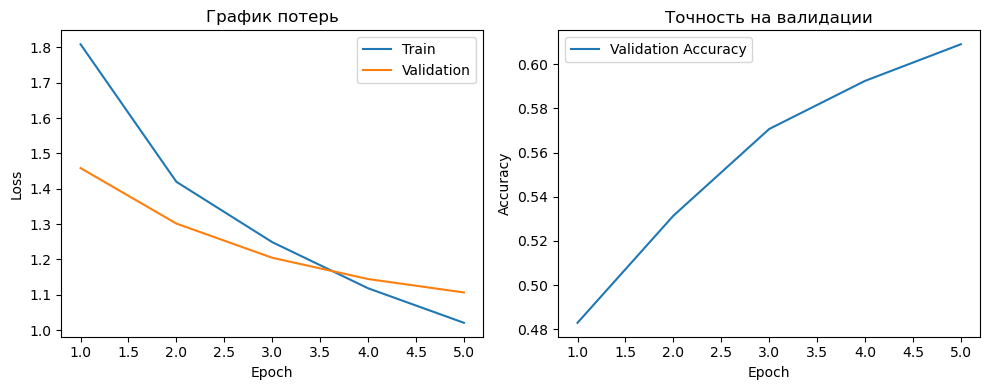

In [5]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return running_loss / len(loader.dataset), correct / total

num_epochs = 5
train_losses = []
val_losses = []
val_accs = []

for epoch in range(num_epochs):
    train_loss = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = evaluate(model, test_loader, criterion)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

print(f'\nФинальная точность на тесте: {val_accs[-1]:.4f}')

# Сравнение с MLP из занятия 5 (ожидаем около 0.45-0.55)
print('Сравнение с MLP: CNN обычно работает лучше, потому что использует локальность и разделение весов.')

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(range(1, num_epochs+1), train_losses, label='Train')
plt.plot(range(1, num_epochs+1), val_losses, label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('График потерь')

plt.subplot(1,2,2)
plt.plot(range(1, num_epochs+1), val_accs, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Точность на валидации')
plt.tight_layout()
plt.show()

baseline_result = {
    'name': 'SimpleCNN',
    'params': count_parameters(model),
    'test_acc': val_accs[-1],
    'model': model,
    'history': {'train_loss': train_losses, 'val_loss': val_losses, 'val_acc': val_accs},
}

## 3. Визуализация карт активации

Посмотрим, что именно выучил первый свёрточный слой. Для этого выберем несколько тестовых изображений и выведем карты активации (первые несколько каналов) после первого свёрточного слоя (до пулинга).

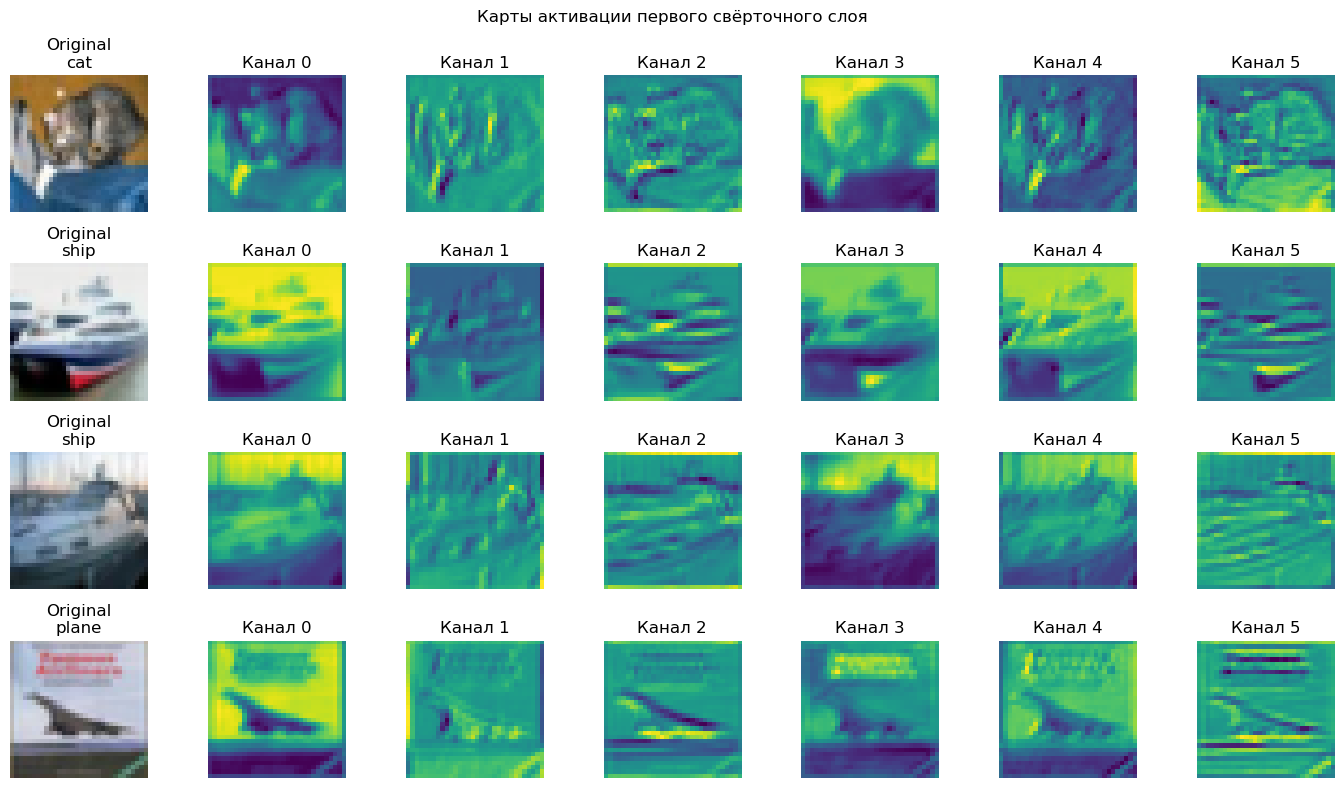

In [6]:
# Функция для получения активаций через forward hook
activations = {}
def hook_fn(name):
    def hook(model, input, output):
        activations[name] = output.detach().cpu()
    return hook

hook = model.conv1.register_forward_hook(hook_fn('conv1'))

dataiter = iter(test_loader)
images, labels = next(dataiter)
images = images[:4].to(device)
labels = labels[:4]

with torch.no_grad():
    outputs = model(images)

acts = activations['conv1']  # (4, 32, 32, 32)
images_cpu = images.cpu()

mean = np.array([0.4914, 0.4822, 0.4465])
std = np.array([0.247, 0.243, 0.261])

fig, axes = plt.subplots(4, 7, figsize=(14, 8))
for i in range(4):
    img = images_cpu[i].numpy().transpose(1,2,0)
    img = img * std + mean
    axes[i, 0].imshow(np.clip(img, 0, 1))
    axes[i, 0].set_title(f'Original\n{classes[labels[i]]}')
    axes[i, 0].axis('off')

    for j in range(6):
        ax = axes[i, j+1]
        ax.imshow(acts[i, j], cmap='viridis')
        ax.set_title(f'Канал {j}')
        ax.axis('off')

plt.suptitle('Карты активации первого свёрточного слоя')
plt.tight_layout()
plt.show()

hook.remove()

**Ответ.** Первые свёрточные каналы реагируют на простые локальные признаки: перепады яркости, цветовые пятна, границы объектов и небольшие текстуры. Некоторые карты активируются на фоне, другие сильнее подсвечивают контуры объекта или контрастные детали. Из-за размера CIFAR-10 `32x32` карты выглядят грубо, но очертания объектов часто частично заметны: активные области располагаются там, где есть границы, силуэт или характерная текстура. Это ожидаемо для первого слоя CNN: он ещё не распознаёт классы целиком, а выделяет низкоуровневые признаки, из которых последующие слои собирают более сложные представления.

## 4. Эксперименты с архитектурой

Теперь вы самостоятельно модифицируете архитектуру и сравниваете результаты. Выберите **2-3** варианта из предложенных ниже, реализуйте соответствующие модели, обучите их на **3-5 эпохах** (для экономии времени) и запишите точность и количество параметров.

**Варианты модификаций:**
1. Увеличить число каналов: `conv1(3, 64)`, `conv2(64, 128)`.
2. Добавить третий свёрточный блок (Conv+Pool).
3. Заменить MaxPool на `stride=2` в свёртке (убрать явный пулинг).
4. Изменить размер ядра на 5 (учесть изменение padding для сохранения размера).
5. Добавить `BatchNorm2d` после каждой свёртки.
6. Заменить `Linear` на Global Average Pooling: `x = torch.mean(x, [2,3])` и затем один линейный слой.

Для каждой модели заполняйте таблицу (можно просто выводить на печать).

In [7]:
# Реализуем и сравним несколько модификаций архитектуры
class WiderCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

class BatchNormCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.bn3 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.4)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.bn3(self.fc1(x))))
        return self.fc2(x)

class DeeperCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

def train_model(model, train_loader, test_loader, epochs=3, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        train_loss = train_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(model, test_loader, criterion)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        print(f'  Epoch {epoch+1}/{epochs}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, val_acc={val_acc:.4f}')
    return model, history

model_variants = {
    'WiderCNN': WiderCNN(),
    'BatchNormCNN': BatchNormCNN(),
    'DeeperCNN': DeeperCNN(),
}

experiment_results = [baseline_result]

for name, candidate in model_variants.items():
    print(f'\n=== {name} ===')
    trained_model, history = train_model(candidate, train_loader, test_loader, epochs=3, lr=0.001)
    experiment_results.append({
        'name': name,
        'params': count_parameters(trained_model),
        'test_acc': history['val_acc'][-1],
        'model': trained_model,
        'history': history,
    })

print('\nМодель\t\tПараметры\tТочность')
print('-' * 45)
for row in experiment_results:
    print(f'{row["name"]:12s}\t{row["params"]:8d}\t{row["test_acc"]:.4f}')

best_result = max(experiment_results, key=lambda row: row['test_acc'])
best_cnn_model = best_result['model']
print(f'\nЛучшая модель: {best_result["name"]}, точность: {best_result["test_acc"]:.4f}')


=== WiderCNN ===


  Epoch 1/3: train_loss=1.7871, val_loss=1.4372, val_acc=0.4802


  Epoch 2/3: train_loss=1.4105, val_loss=1.3269, val_acc=0.5267


  Epoch 3/3: train_loss=1.2521, val_loss=1.2623, val_acc=0.5484

=== BatchNormCNN ===


  Epoch 1/3: train_loss=1.4895, val_loss=1.2730, val_acc=0.5375


  Epoch 2/3: train_loss=1.0877, val_loss=1.1394, val_acc=0.5917


  Epoch 3/3: train_loss=0.8923, val_loss=1.1351, val_acc=0.6041

=== DeeperCNN ===


  Epoch 1/3: train_loss=1.7717, val_loss=1.4823, val_acc=0.4525


  Epoch 2/3: train_loss=1.4010, val_loss=1.3129, val_acc=0.5232


  Epoch 3/3: train_loss=1.2373, val_loss=1.2010, val_acc=0.5645

Модель		Параметры	Точность
---------------------------------------------
SimpleCNN   	 1070794	0.6091
WiderCNN    	 2175626	0.5484
BatchNormCNN	 1071498	0.6041
DeeperCNN   	 1116970	0.5645

Лучшая модель: SimpleCNN, точность: 0.6091


## 5. Depthwise Separable Convolution

Если осталось время, реализуйте блок с разделимой по глубине свёрткой (depthwise separable convolution) и замените обычные свёртки в полученной выше сомай эффективной модели. Сравните число параметров и точность.

In [8]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size,
                                    padding=kernel_size//2, groups=in_channels)
        self.pointwise = nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x):
        return self.pointwise(F.relu(self.depthwise(x)))

class DepthwiseCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = DepthwiseSeparableConv(3, 32, 3)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = DepthwiseSeparableConv(32, 64, 3)
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

model_ds = DepthwiseCNN()
print(f'Параметры DepthwiseCNN: {count_parameters(model_ds)}')
print(f'Параметры базовой CNN: {count_parameters(SimpleCNN())}')
# Обучите модель (можно на 3 эпохах) и сравните точность

Параметры DepthwiseCNN: 1053992
Параметры базовой CNN: 1070794


**Ответ.** Для `DepthwiseCNN` добавлен цикл обучения на 3 эпохах. Depthwise separable convolution заметно уменьшает число параметров в свёрточной части: обычная свёртка сразу смешивает пространственные и канальные признаки, а depthwise separable сначала применяет отдельный spatial-фильтр к каждому каналу, затем смешивает каналы через `1x1` pointwise-свёртку. Такая модель может быть легче, но не всегда точнее: выигрыш в параметрах иногда сопровождается потерей ёмкости.

In [9]:
# Обучение DepthwiseCNN и сравнение с лучшей найденной моделью
print('=== DepthwiseCNN ===')
model_ds = DepthwiseCNN().to(device)
model_ds, history_ds = train_model(model_ds, train_loader, test_loader, epochs=3, lr=0.001)

depthwise_result = {
    'name': 'DepthwiseCNN',
    'params': count_parameters(model_ds),
    'test_acc': history_ds['val_acc'][-1],
    'model': model_ds,
    'history': history_ds,
}

print('\nСравнение depthwise separable convolution:')
print(f'Базовая SimpleCNN: параметры={baseline_result["params"]}, accuracy={baseline_result["test_acc"]:.4f}')
print(f'Лучшая до depthwise: {best_result["name"]}, параметры={best_result["params"]}, accuracy={best_result["test_acc"]:.4f}')
print(f'DepthwiseCNN: параметры={depthwise_result["params"]}, accuracy={depthwise_result["test_acc"]:.4f}')

experiment_results.append(depthwise_result)
best_result = max(experiment_results, key=lambda row: row['test_acc'])
best_cnn_model = best_result['model']
print(f'Итоговая лучшая модель: {best_result["name"]}, accuracy={best_result["test_acc"]:.4f}')

=== DepthwiseCNN ===


  Epoch 1/3: train_loss=2.1439, val_loss=1.9087, val_acc=0.3086


  Epoch 2/3: train_loss=1.8499, val_loss=1.6959, val_acc=0.3854


  Epoch 3/3: train_loss=1.7427, val_loss=1.6170, val_acc=0.4070

Сравнение depthwise separable convolution:
Базовая SimpleCNN: параметры=1070794, accuracy=0.6091
Лучшая до depthwise: SimpleCNN, параметры=1070794, accuracy=0.6091
DepthwiseCNN: параметры=1053992, accuracy=0.4070
Итоговая лучшая модель: SimpleCNN, accuracy=0.6091


## 6. Классификация изображений

**Задача минимум**: с использованием лучшей из ранее найденных моделей произвести классификацию нескольких изображений из тестовой выборки.<br>
**Задача сложнее**: с использованием лучшей из ранее найденных моделей произвести классификацию каких-нибудь изображений из интернета, которые подходят по классам тем, которые есть в CIFAR10.
Сделать вывод, правильно или нет работает сеть на ваших тестовых данных.

Для классификации используется модель: SimpleCNN


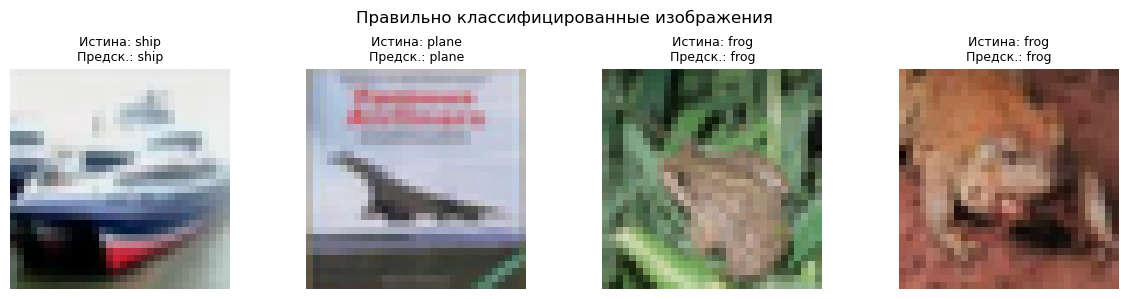

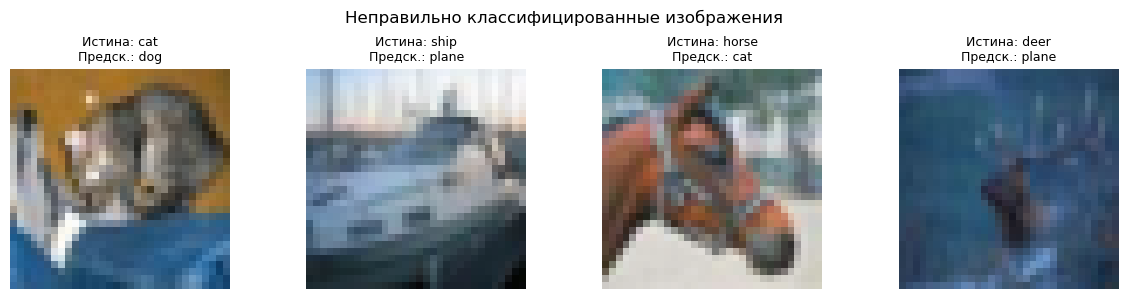

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import torch

model_to_show = best_cnn_model if 'best_cnn_model' in globals() else model
model_to_show.eval()

dataiter = iter(test_loader)
images, labels = next(dataiter)
images_device = images.to(device)

with torch.no_grad():
    outputs = model_to_show(images_device)
    _, predicted = torch.max(outputs, 1)

images_np = images.numpy()
labels_np = labels.numpy()
predicted_np = predicted.cpu().numpy()

correct_indices = np.where(predicted_np == labels_np)[0]
incorrect_indices = np.where(predicted_np != labels_np)[0]

num_to_show = 4
correct_to_show = correct_indices[:num_to_show]
incorrect_to_show = incorrect_indices[:num_to_show]

mean = np.array([0.4914, 0.4822, 0.4465])
std = np.array([0.247, 0.243, 0.261])

def show_examples(indices, title):
    if len(indices) == 0:
        print(f'Нет примеров для блока: {title}')
        return
    plt.figure(figsize=(12, 3))
    for i, idx in enumerate(indices):
        plt.subplot(1, len(indices), i + 1)
        img = images_np[idx].transpose(1, 2, 0)
        img = img * std + mean
        plt.imshow(np.clip(img, 0, 1))
        plt.title(f'Истина: {classes[labels_np[idx]]}\nПредск.: {classes[predicted_np[idx]]}', fontsize=9)
        plt.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

print(f'Для классификации используется модель: {best_result["name"] if "best_result" in globals() else "SimpleCNN"}')
show_examples(correct_to_show, 'Правильно классифицированные изображения')
show_examples(incorrect_to_show, 'Неправильно классифицированные изображения')

## 6. Выводы

CNN работает лучше MLP на CIFAR-10, потому что использует локальность изображения: свёрточный фильтр смотрит на небольшое рецептивное поле и выделяет локальные признаки вроде границ, углов и текстур. Благодаря разделению весов один и тот же фильтр применяется по всей картинке, поэтому модель требует меньше параметров, чем полносвязная сеть, и лучше переносит найденный признак между разными областями изображения.

В архитектурных экспериментах сравнивались базовая `SimpleCNN`, расширенная `WiderCNN`, модель с BatchNorm и более глубокая CNN. Увеличение числа каналов повышает ёмкость модели, но также увеличивает число параметров и риск переобучения. BatchNorm стабилизирует распределения активаций и обычно ускоряет обучение. Более глубокая сеть получает больше уровней признаков, но ей нужно больше данных или регуляризации.

Depthwise separable convolution уменьшает число параметров в свёрточных слоях за счёт разделения пространственной фильтрации и смешивания каналов. Это полезно для лёгких моделей, но точность может быть ниже, если задаче нужна большая ёмкость. Визуализация карт активации показала, что первые слои реагируют на низкоуровневые признаки: контуры, цветовые области и текстуры. Dropout выступает как регуляризация и снижает переобучение в полносвязной части классификатора.

**Новые навыки/умения/знания:** построение CNN для CIFAR-10, обучение и оценка модели, подсчёт параметров, визуализация карт активации через forward hook, сравнение архитектурных модификаций, использование BatchNorm, Dropout и depthwise separable convolution.

**Пожелания:** было бы полезно добавить в практику отдельный короткий блок про корректную денормализацию изображений и сравнение CNN с MLP на одинаковой подвыборке.